In [76]:
import os
# Fixes the C-level OpenMP conflict between PyTorch and NumPy/Matplotlib
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

In [77]:
import torch
import torchmetrics
import numpy as np
import matplotlib.pyplot as plt

In [78]:
from torch import nn

In [79]:
sigmoid = nn.Sigmoid()
x = torch.linspace(-25, 25, 100)

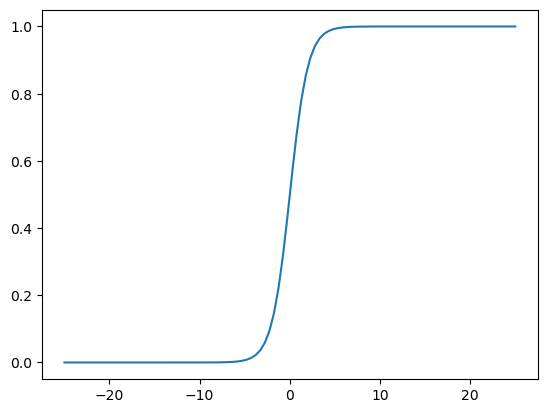

In [80]:
plt.figure()
plt.plot(x.numpy(), sigmoid(x).numpy())
plt.show()

Problem graident always near 0.25 no learning to previous last layers, vanishing gradient( saturating) at high inputs

In [81]:
# Weight Initialization from the normal distribution
X = torch.tensor(np.random.uniform(low=0, high=5.0, size=(50, 3)), dtype=torch.float)
X[:4]

tensor([[1.1002, 1.3577, 4.2244],
        [4.6540, 1.0521, 4.7233],
        [1.4140, 0.1357, 2.5756],
        [4.2326, 2.0460, 0.2215]])

In [82]:
weights = nn.Parameter(torch.randn(3, 10))
weights

Parameter containing:
tensor([[ 0.0507,  0.8744,  0.8362,  1.2523,  1.4155,  1.0775,  0.4157,  0.8751,
         -0.4568,  2.0837],
        [-0.6870, -1.3961,  0.4168, -1.0418,  0.3460, -0.1358,  0.1900, -1.0000,
          0.8785,  0.3805],
        [ 2.2882, -0.0258, -0.3664,  1.0645, -2.0024, -1.3955, -0.1751,  0.0662,
         -1.0159,  0.0409]], requires_grad=True)

Here we have three input neurons, each hidden neuron has its own weight which is always going to be 3 (input neurons)

then the layer has 10 neurons each ten neuron has 3 weights


now because of 10 neurons the output is 10 dimensional

Each column in a weight matrix is a neuron weight

In [83]:
X[0] @ weights

tensor([ 8.7893, -1.0425, -0.0620,  4.4599, -6.4317, -4.8940, -0.0246, -0.1153,
        -3.6012,  2.9820], grad_fn=<SqueezeBackward4>)

In [84]:
# so
activation = nn.Sigmoid()
y = torch.tensor(data=np.random.randint(low=0, high=2, size=(50, 1)), dtype=torch.float)
loss = nn.BCELoss()


In [119]:
class model(nn.Module):
    def __init__(self, n_hidden_1, n_hidden_2, n_hidden_3, n_hidden_4):
        super().__init__()
        self.sigmoid = nn.Sigmoid()
        self.weights_1 = nn.Parameter(torch.randn(size=(3, n_hidden_1), dtype=torch.float))
        self.weights_2 = nn.Parameter(torch.randn(size=(n_hidden_1, n_hidden_2), dtype=torch.float))
        self.weights_3 = nn.Parameter(torch.randn(size=(n_hidden_2, n_hidden_3), dtype=torch.float))
        self.weights_4 = nn.Parameter(torch.randn(size=(n_hidden_3, n_hidden_4), dtype=torch.float))
        self.output_layer = nn.Linear(n_hidden_4, 1)
        
    def forward(self, X):
            h1 = X @ self.weights_1
            h1 = self.sigmoid(h1)        
            h2 = h1 @ self.weights_2
            h2 = self.sigmoid(h2)
            h3 = h2 @ self.weights_3
            h3 = self.sigmoid(h3)
            h4 = h3 @ self.weights_4
            h4 = self.sigmoid(h4)
            return self.sigmoid(self.output_layer(h4))
model = model(24, 16, 8, 4)

1537 epoch required


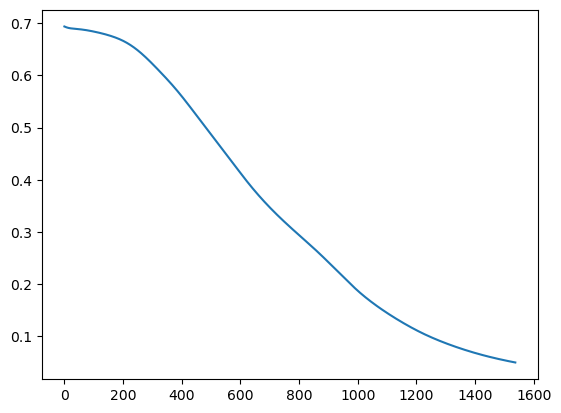

In [120]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
train_loss = []
for i in range(5000):
    model.train()
    optimizer.zero_grad()
    error = loss(model(X), y)
    error.backward()
    optimizer.step()
    train_loss.append(error.item())
    if error < 0.05 :
        print(f'{i} epoch required')
        break
plt.figure()
plt.plot(train_loss)
plt.show()

the model is failing to learn because the weights has not been changed

This occured for two reasons one is that there is normal initializatoin, ( weight and X) are random varibles during multiplication their variance are multiplied whihc leads to bigger number and after sigmoid they saturate so their derivative at zero which means no update

the second reason could occur vanishing gradient where sigmoid max grad is 0.25 so gradient is killed reaching early layers, early layers get no update but the newewer layer gets

Sigmoid is not good in both ways forward causes saturation and backward causes vanishing grad.

In [121]:
#Same thing occurs with uniform distribution

class model(nn.Module):
    def __init__(self, n_hidden_1, n_hidden_2, n_hidden_3, n_hidden_4):
        super().__init__()
        self.sigmoid = nn.Sigmoid()
        self.weights_1 = nn.Parameter(torch.randint(low=-1, high=2, size=(3, n_hidden_1), dtype=torch.float))
        self.weights_2 = nn.Parameter(torch.randint(low=-1, high=2, size=(n_hidden_1, n_hidden_2), dtype=torch.float))
        self.weights_3 = nn.Parameter(torch.randint(low=-1, high=2, size=(n_hidden_2, n_hidden_3), dtype=torch.float))
        self.weights_4 = nn.Parameter(torch.randint(low=-1, high=2, size=(n_hidden_3, n_hidden_4), dtype=torch.float))
        self.output_layer = nn.Linear(n_hidden_4, 1)
        
    def forward(self, X):
            h1 = X @ self.weights_1
            h1 = self.sigmoid(h1)        
            h2 = h1 @ self.weights_2
            h2 = self.sigmoid(h2)
            h3 = h2 @ self.weights_3
            h3 = self.sigmoid(h3)
            h4 = h3 @ self.weights_4
            h4 = self.sigmoid(h4)
            return self.sigmoid(self.output_layer(h4))
model = model(24, 16, 8, 4)

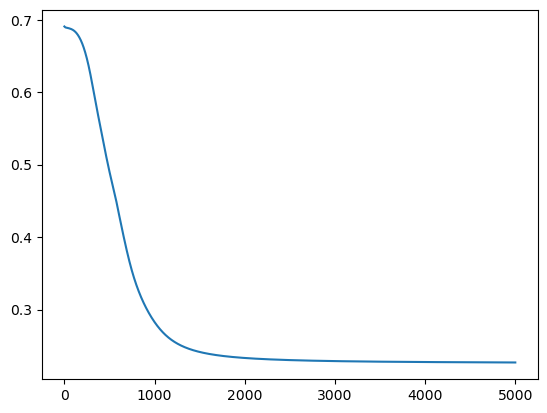

In [122]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
train_loss = []
for i in range(5000):
    model.train()
    optimizer.zero_grad()
    error = loss(model(X), y)
    error.backward()
    optimizer.step()
    train_loss.append(error.item())
    if error < 0.05 :
        print(f'{i} epoch required')
        break
plt.figure()
plt.plot(train_loss)
plt.show()

To satisfy the mathematical condition that variance remains stable in both directions, Glorot and Bengio derived a smart scaling factor based on the number of input and output connections of the layer.Instead of a generic distribution, Xavier Initialization scales the distribution's boundaries using the layer dimensions:For a Uniform Distribution ($\mathcal{U}[-a, a]$):$$a = \sqrt{\frac{6}{n_{in} + n_{out}}}$$For a Normal Distribution ($\mathcal{N}(0, \sigma^2)$):$$\sigma = \sqrt{\frac{2}{n_{in} + n_{out}}}$$

(Where $n_{in}$ is the number of incoming neurons to the layer, and $n_{out}$ is the number of outgoing neurons)

The variance must be equal acrosss forward and backward


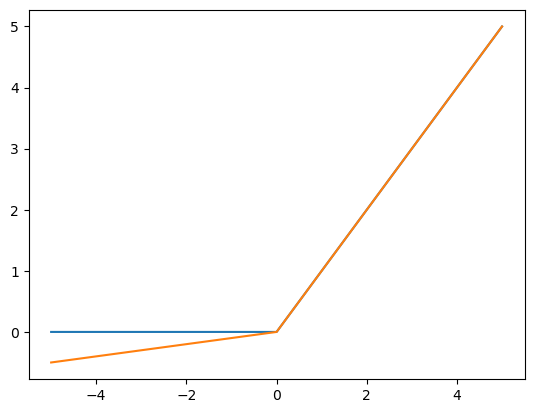

In [123]:
lrelu = nn.LeakyReLU(0.1)
relu = nn.ReLU()
x = np.linspace(-5, 5, 25)
plt.figure()
plt.plot(x, relu(torch.tensor(x)))
plt.plot(x, lrelu(torch.tensor(x)))
plt.show()

derivative zero at -ve side.
    

A neu ron dies when its weights get tweaked in such a way that the in put of the ReLU func tion (i.e.,
the weighted sum of the neu ron’s in puts plus its bias term) is neg a tive for all in stances in the train ing set.
When this hap pens, it just keeps out putting ze ros, and gra di ent de scent does not affect it any more be cause
the gra di ent of the ReLU func tion is zero when its in put is neg a tive

In [124]:
nn.init.kaiming_normal_(torch.tensor([4, 2, 2.5 ,10]).reshape(2, 2))

tensor([[-0.0037, -0.3090],
        [ 0.2968,  0.9814]])

737 epoch required


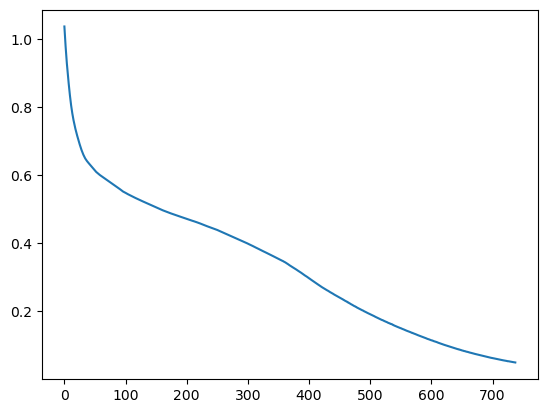

In [125]:
def initialization(m):
    if isinstance(m, nn.Linear):
        nn.init.kaiming_normal_(m.weight, a=0.1, nonlinearity='leaky_relu')
        nn.init.zeros_(m.bias)


class model(nn.Module):
    def __init__(self, n_hidden_1, n_hidden_2, n_hidden_3, n_hidden_4):
        super().__init__()
        self.relu = nn.LeakyReLU(0.1)
        self.sigmoid = nn.Sigmoid()
        self.layer_1 = nn.Linear(3, n_hidden_1)
        self.layer_2 = nn.Linear(n_hidden_1, n_hidden_2)
        self.layer_3 = nn.Linear(n_hidden_2, n_hidden_3)
        self.layer_4 = nn.Linear(n_hidden_3, n_hidden_4)
        self.output_layer = nn.Linear(n_hidden_4, 1)
    def forward(self, X):
            h1 = self.layer_1(X)
            h1 = self.relu(h1)        
            h2 = self.layer_2(h1)
            h2 = self.relu(h2)
            h3 = self.layer_3(h2)
            h3 = self.relu(h3)
            h4 = self.layer_4(h3)
            h4 = self.relu(h4)
            return self.sigmoid(self.output_layer(h4))
model = model(24, 16, 8, 4).apply(initialization)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
train_loss = []

for i in range(5000):
    model.train()
    optimizer.zero_grad()
    error = loss(model(X), y)
    error.backward()
    optimizer.step()
    train_loss.append(error.item())
    if error < 0.05 :
        print(f'{i} epoch required')
        break
plt.figure()
plt.plot(train_loss)
plt.show()
        

1030 epoch required


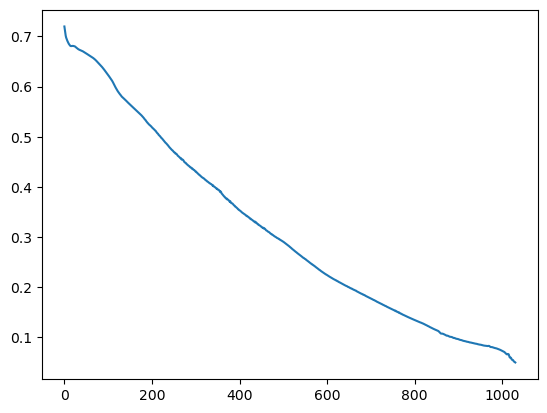

In [159]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

def initialization(m):
    if isinstance(m, nn.Linear):
        nn.init.kaiming_normal_(m.weight, a=0.1, nonlinearity='leaky_relu')
        nn.init.zeros_(m.bias)

class model(nn.Module):
    def __init__(self, n_hidden_1, n_hidden_2, n_hidden_3, n_hidden_4):
        super().__init__()
        self.relu_1 = nn.PReLU(num_parameters=1, init=0.1)
        self.relu_2 = nn.PReLU(num_parameters=1, init=0.1)
        self.relu_3 = nn.PReLU(num_parameters=1, init=0.1)
        self.relu_4 = nn.PReLU(num_parameters=1, init=0.1)
        self.sigmoid = nn.Sigmoid()
        self.layer_1 = nn.Linear(3, n_hidden_1)
        self.layer_2 = nn.Linear(n_hidden_1, n_hidden_2)
        self.layer_3 = nn.Linear(n_hidden_2, n_hidden_3)
        self.layer_4 = nn.Linear(n_hidden_3, n_hidden_4)
        self.output_layer = nn.Linear(n_hidden_4, 1)

    def forward(self, X):
        h1 = self.layer_1(X)
        h1 = self.relu_1(h1)        
        h2 = self.layer_2(h1)
        h2 = self.relu_2(h2)
        h3 = self.layer_3(h2)
        h3 = self.relu_3(h3)
        h4 = self.layer_4(h3)
        h4 = self.relu_4(h4)
        return self.sigmoid(self.output_layer(h4))

model = model(24, 16, 8, 4).apply(initialization)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
train_loss = []

for i in range(5000):
    model.train()
    optimizer.zero_grad()
    error = loss(model(X), y)
    error.backward()
    optimizer.step()
    train_loss.append(error.item())
    if error < 0.05:
        print(f'{i} epoch required')
        break

plt.figure()
plt.plot(train_loss)
plt.show()

In [160]:
model.eval() # Good practice before checking parameters

for name, param in model.named_parameters():
    if 'relu' in name:
        print(f"Layer: {name} | Learned Slope (a): {param.data}")

Layer: relu_1.weight | Learned Slope (a): tensor([0.2284])
Layer: relu_2.weight | Learned Slope (a): tensor([-0.4714])
Layer: relu_3.weight | Learned Slope (a): tensor([-0.7788])
Layer: relu_4.weight | Learned Slope (a): tensor([-0.0941])


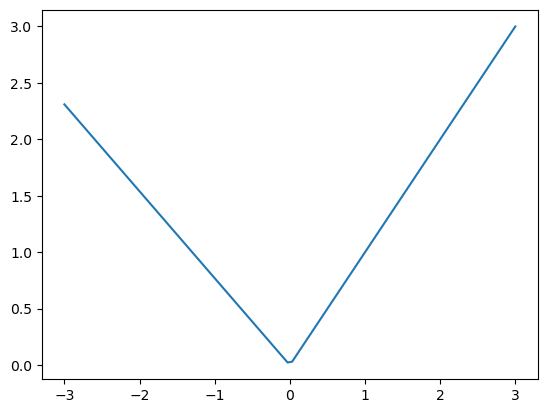

In [174]:
a = nn.LeakyReLU(-0.77)
plt.figure()
plt.plot(np.linspace(-3, 3, 100),  a(torch.tensor(np.linspace(-3, 3, 100))))
plt.show()

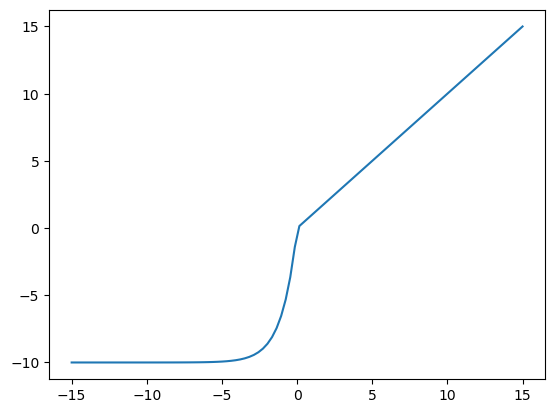

In [185]:
a = nn.ELU(10.0)
plt.figure()
plt.plot(np.linspace(-15, 15, 100),  a(torch.tensor(np.linspace(-15, 15, 100))))
plt.show()

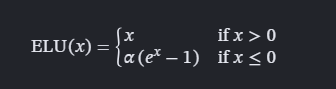

In [186]:
a(torch.tensor(-250.0))

tensor(-10.)